# Previsão de Churn — Pipeline de Treinamento (Fase 1)

**Problema de negócio:** identificar clientes de uma operadora de telecom com alta chance de cancelar o contrato (*churn*), para que o time de retenção aja antes do cancelamento.

**Base:** [Telco Customer Churn (Kaggle / IBM)](https://www.kaggle.com/datasets/blastchar/telco-customer-churn), 7.043 clientes e 21 colunas, salva em `data/telco_churn.csv`.

**Tipo de problema:** classificação binária (`Churn` = Yes/No).

Este notebook documenta e justifica cada decisão. O script `scripts/train.py` reproduz o mesmo pipeline e gera os artefatos usados pela API.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

# Caminho relativo: o notebook fica em notebooks/, os dados em data/
BASE_DIR = Path.cwd().parent
DATA_PATH = BASE_DIR / "data" / "telco_churn.csv"
RANDOM_STATE = 42

## 1. Carregamento e análise exploratória

In [2]:
df = pd.read_csv(DATA_PATH)
print(df.shape)
df.head()

(7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


A coluna `TotalCharges` vem como texto porque clientes recém-contratados (`tenure = 0`) têm um espaço em branco no lugar do valor. Convertendo para número, esses casos viram `NaN` — é por isso que o pipeline precisa de **imputação de nulos**.

In [3]:
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
df.isna().sum()[lambda s: s > 0]

TotalCharges    11
dtype: int64

Churn
No     0.735
Yes    0.265
Name: proportion, dtype: float64


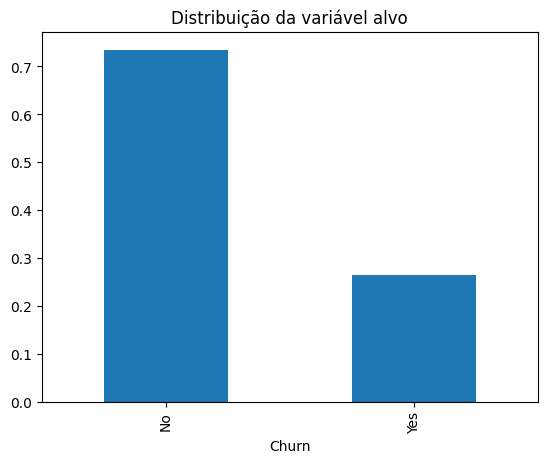

In [4]:
taxa = df["Churn"].value_counts(normalize=True).round(3)
print(taxa)
taxa.plot(kind="bar", title="Distribuição da variável alvo")
plt.show()

As classes são **desbalanceadas** (cerca de 1 em cada 4 clientes cancela). Por isso:
- a divisão dos dados será **estratificada**;
- a acurácia sozinha engana, então a seleção do modelo usará **ROC-AUC** e o relatório trará também **F1**.

In [5]:
df.groupby("Contract")["Churn"].apply(lambda s: (s == "Yes").mean()).round(3)

Contract
Month-to-month    0.427
One year          0.113
Two year          0.028
Name: Churn, dtype: float64

**Seleção de variáveis.** Ficamos com 12 colunas ligadas a tempo de casa, valores pagos, perfil e serviços contratados. `customerID` é só identificador e não entra no modelo. Menos colunas também deixam o contrato da API mais simples para quem consome.

In [9]:
NUMERIC = ["tenure", "MonthlyCharges", "TotalCharges", "SeniorCitizen"]
CATEGORICAL = ["Partner", "Dependents", "InternetService", "OnlineSecurity",
               "TechSupport", "Contract", "PaperlessBilling", "PaymentMethod"]

X = df[NUMERIC + CATEGORICAL]
y = (df["Churn"] == "Yes").astype(int)
X.shape

(7043, 12)

## 2. Divisão treino / validação / teste

- **70% treino**: ajusta os modelos.
- **15% validação**: compara os candidatos e escolhe o melhor.
- **15% teste**: usado **uma única vez** no final, para uma estimativa honesta do desempenho.

`stratify` mantém a proporção de churn igual nos três conjuntos; `random_state` fixo garante reprodutibilidade.

In [7]:
from sklearn.model_selection import train_test_split

X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, stratify=y, random_state=RANDOM_STATE)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, stratify=y_temp, random_state=RANDOM_STATE)

for nome, alvo in [("treino", y_train), ("validação", y_val), ("teste", y_test)]:
    print(f"{nome:<10} {len(alvo):>5} linhas | churn = {alvo.mean():.3f}")

treino      4930 linhas | churn = 0.265
validação   1056 linhas | churn = 0.265
teste       1057 linhas | churn = 0.266


## 3. Pré-processamento

Todo o pré-processamento fica **dentro do `Pipeline`**, junto com o modelo:
- evita *data leakage* (médias, medianas e categorias são aprendidas só no treino);
- a API recebe dados crus e o mesmo arquivo `.joblib` aplica exatamente as mesmas transformações.

| Tipo | Imputação | Transformação |
| --- | --- | --- |
| Numérico | mediana (robusta a outliers) | `StandardScaler` |
| Categórico | valor mais frequente | `OneHotEncoder(handle_unknown="ignore")` |

In [8]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler


def build_preprocessor() -> ColumnTransformer:
    numeric = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
    ])
    categorical = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore")),
    ])
    return ColumnTransformer([
        ("num", numeric, NUMERIC),
        ("cat", categorical, CATEGORICAL),
    ])


build_preprocessor()

,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True
,force_int_remainder_cols,'deprecated'
,missing_values,nan
,strategy,'median'
,fill_value,None


## 4. Treino e seleção do modelo

Comparamos dois candidatos no conjunto de **validação**:
- **Regressão Logística**: linear, rápida e interpretável (modelo usado em aula para churn).
- **Random Forest**: captura interações não lineares.

Ambos usam `class_weight="balanced"` para compensar o desbalanceamento. O critério de escolha é o **ROC-AUC**, que mede a capacidade de ordenar clientes por risco independentemente do limiar.

In [10]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, f1_score, precision_score,
                             recall_score, roc_auc_score)


def evaluate(pipeline, X, y, threshold=0.5) -> dict:
    proba = pipeline.predict_proba(X)[:, 1]
    pred = (proba >= threshold).astype(int)
    return {
        "accuracy": round(accuracy_score(y, pred), 4),
        "precision": round(precision_score(y, pred), 4),
        "recall": round(recall_score(y, pred), 4),
        "f1": round(f1_score(y, pred), 4),
        "roc_auc": round(roc_auc_score(y, proba), 4),
    }


candidates = {
    "logistic_regression": LogisticRegression(max_iter=1000, class_weight="balanced"),
    "random_forest": RandomForestClassifier(n_estimators=300, min_samples_leaf=5,
                                            class_weight="balanced",
                                            random_state=RANDOM_STATE, n_jobs=-1),
}

val_results = {}
for name, estimator in candidates.items():
    pipe = Pipeline([("preprocessor", build_preprocessor()), ("model", estimator)])
    pipe.fit(X_train, y_train)
    val_results[name] = evaluate(pipe, X_val, y_val)

pd.DataFrame(val_results).T

,accuracy,precision,recall,f1,roc_auc
logistic_regression,0.7348,0.5000,0.8214,0.6216,0.8395
random_forest,0.7604,0.5344,0.7500,0.6241,0.8364


In [11]:
best_name = max(val_results, key=lambda n: val_results[n]["roc_auc"])
print("Modelo escolhido:", best_name)

Modelo escolhido: logistic_regression


O modelo com maior ROC-AUC na validação é o escolhido. Em empate técnico, a Regressão Logística é preferível por ser mais leve e explicável.

## 5. Avaliação final no conjunto de teste

O modelo escolhido é re-treinado com **treino + validação** (mais dados, mesmos hiperparâmetros) e avaliado **uma única vez** no teste.

{'accuracy': 0.7483, 'precision': 0.5178, 'recall': 0.7758, 'f1': 0.6211, 'roc_auc': 0.843}
              precision    recall  f1-score   support

        Fica       0.90      0.74      0.81       776
     Cancela       0.52      0.78      0.62       281

    accuracy                           0.75      1057
   macro avg       0.71      0.76      0.72      1057
weighted avg       0.80      0.75      0.76      1057



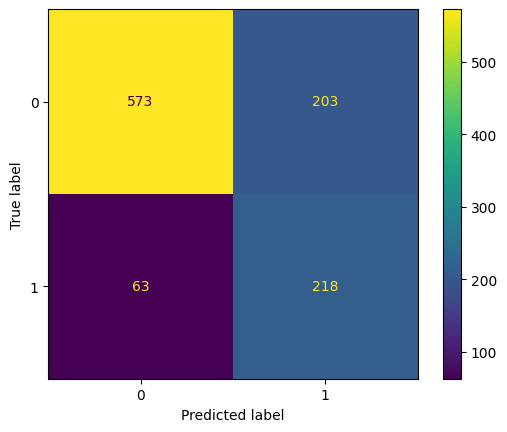

In [12]:
from sklearn.base import clone
from sklearn.metrics import classification_report, ConfusionMatrixDisplay

final_pipeline = Pipeline([
    ("preprocessor", build_preprocessor()),
    ("model", clone(candidates[best_name])),
])
final_pipeline.fit(pd.concat([X_train, X_val]), pd.concat([y_train, y_val]))

test_metrics = evaluate(final_pipeline, X_test, y_test)
print(test_metrics)
print(classification_report(y_test, final_pipeline.predict(X_test), target_names=["Fica", "Cancela"]))
ConfusionMatrixDisplay.from_estimator(final_pipeline, X_test, y_test)
plt.show()

## 6. Conclusão

- O pipeline completo (imputação + codificação + escalonamento + modelo) é um único objeto, pronto para serialização.
- As métricas do teste são a referência oficial do projeto e ficam salvas em `reports/metrics.json`.
- Para gerar os artefatos usados pela API, rode na raiz do projeto: `python scripts/train.py`.